# 3 · Internal repeats by self-alignment

Smith–Waterman alignment of the sequence against itself (BLOSUM62, linear gap −8, upper triangle),
with Waterman–Eggert declumping so that each reported alignment is distinct. Significance is a
z-score against shuffled sequences. Low-complexity regions dominate unless masked.

In [1]:
import matplotlib.pyplot as plt
from aarepeats import EXAMPLES, read_fasta
from aarepeats import plotting as P

P.use_style()
DATA = "../data"
seq = EXAMPLES["toy"]
print(len(seq), seq)

66 MAMAMAMAMAMAPRTEINSEQENCEAAAAAAHHHHTESTSTSTSTSTSSGSGSGSGSWWWWWGSGS


In [2]:
from aarepeats import find_internal_repeats

toy = EXAMPLES["toy_long"]
for masked in (False, True):
    print("LCR masking:", masked)
    for a in find_internal_repeats(toy, min_score=40, max_alignments=4, mask_low_complexity=masked, n_shuffles=20):
        print(f"  {a.start1 + 1}-{a.end1} ~ {a.start2 + 1}-{a.end2}  score {a.score:.0f}  z={a.zscore:.1f}  {a.kind}")
        print(f"    {a.aligned1[:60]}\n    {a.aligned2[:60]}")

LCR masking: False
  12-170 ~ 14-174  score 362  z=54.9  tandem
    MAMAMAMAMAMAMAMAMAAPRTEINSEQENCEAAQAAAQHMAMAHHHTESTSTSTSTSTS
    MAMAMAMAMAMAMAMAAPRTEINSEQENCEAAQAAAQHMAMAHHHTESTSTSTSTSTSSG
  85-154 ~ 141-212  score 133  z=15.8  tandem
    WGSGSACDEFGHIKACDE-FGHIKACDE-FGHIKACDEFGHIKMAMAMAMAMAMACDEFG
    FGHIKACDEFGHIKGSGSGSGSTESTTESTTESTACDEFGHIKAPRTEINSEQENCEAAA
  30-49 ~ 184-203  score 94  z=9.1  dispersed
    APRTEINSEQENCEAAQAAA
    APRTEINSEQENCEAAAAAA
  2-11 ~ 202-211  score 53  z=2.1  dispersed
    ASACDEFGHI
    AAACDEFGHI
LCR masking: True
  92-141 ~ 101-150  score 151  z=38.2  tandem
    DEFGHIKACDEFGHIKACDEFGHIKACDEFGHIKMAMAMAMAMAMACDEF
    DEFGHIKACDEFGHIKACDEFGHIKMAMAMAMAMAMACDEFGHIKACDEF
  100-146 ~ 138-184  score 83  z=18.1  tandem
    CDEFGHIKACDEFGHIKACDEFGHIKMAMAMAMAMAMACDEFGHIKA
    CDEFGHIKACDEFGHIKGSGSGSGSTESTTESTTESTACDEFGHIKA
  4-11 ~ 99-106  score 48  z=7.8  dispersed
    ACDEFGHI
    ACDEFGHI
  4-11 ~ 108-115  score 48  z=7.8  dispersed
    ACDEFGHI
    ACD

## Sup35: diverged oligopeptide repeats (PQGGYQQYN)

3-82 ~ 21-101  offset 18  identity 52%  z=5.9
6-40 ~ 85-122  offset 79  identity 39%  z=-3.4


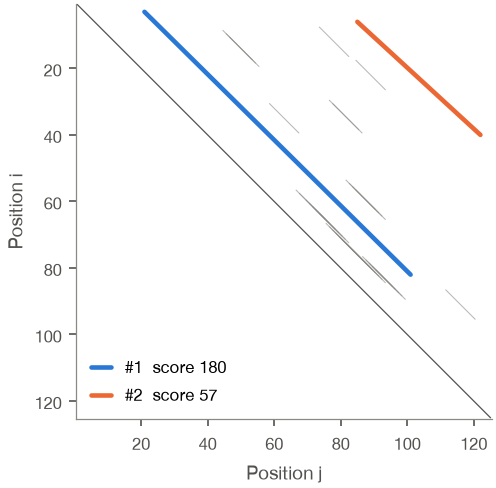

In [3]:
_, sup = read_fasta(f"{DATA}/P05453.fasta")[0]
al = find_internal_repeats(sup[:125], min_score=30, max_alignments=3, n_shuffles=50)
for a in al:
    print(f"{a.start1 + 1}-{a.end1} ~ {a.start2 + 1}-{a.end2}  offset {a.offset}  identity {a.identity:.0%}  z={a.zscore:.1f}")
P.plot_dotplot(sup[:125], al)
plt.show()